# CLIP and SigLIP2 evaluation
This notebook compares saved predictions on the same 50 images and
ten candidate descriptions. It verifies results, compares accuracy
and resource measurements, and inspects recognition errors.


Output zip file from 04b_siglip2 is needed to upload here.

In [1]:
from pathlib import Path
import zipfile
import json
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files

project = Path("/content/product_recognition")
project.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()
zip_names = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]
assert len(zip_names) == 1, "Upload the combined backup ZIP."

with zipfile.ZipFile(zip_names[0]) as archive:
    for name in archive.namelist():
        destination = (project / name).resolve()
        assert destination.is_relative_to(project.resolve())
    archive.extractall(project)

del uploaded

evaluation = project / "evaluation"
evaluation.mkdir(exist_ok=True)

manifest = pd.read_csv(project / "results/image_manifest.csv")

with open(project / "results/candidate_labels.json") as file:
    products = json.load(file)

assert len(manifest) == 50
assert manifest["image_id"].is_unique

for row in manifest.itertuples(index=False):
    path = project / row.image_file
    assert hashlib.sha256(path.read_bytes()).hexdigest() == row.sha256

print("Verified images:", len(manifest))
print("Source photographs:", manifest["product"].nunique())
print("Candidates:", len(products))

Saving pair4_both_models_backup.zip to pair4_both_models_backup.zip
Verified images: 50
Source photographs: 10
Candidates: 10


In [2]:
all_predictions = []
all_scores = []
summary_records = []

for model_label, prefix in [
    ("CLIP", "clip"),
    ("SigLIP2", "siglip2"),
]:
    predictions = pd.read_csv(
        project / f"outputs/{prefix}_predictions.csv"
    )
    scores = pd.read_csv(
        project / f"outputs/{prefix}_candidate_scores.csv"
    )

    assert predictions["image_id"].is_unique
    assert set(predictions["image_id"]) == set(manifest["image_id"])
    assert set(scores["image_id"]) == set(manifest["image_id"])
    assert not scores.duplicated(["image_id", "candidate"]).any()
    assert np.isfinite(scores["score"]).all()
    assert (predictions["model"] == model_label).all()

    predictions = predictions.set_index("image_id").loc[
        manifest["image_id"]
    ].reset_index()

    for column in ["product", "condition", "image_file"]:
        assert np.array_equal(predictions[column], manifest[column])

    # Check saved predictions against candidate rankings
    for row in predictions.itertuples(index=False):
        ranked = scores[
            scores["image_id"] == row.image_id
        ].sort_values("rank")

        assert set(ranked["candidate"]) == set(products)
        assert ranked["rank"].tolist() == list(range(1, 11))
        assert np.all(np.diff(ranked["score"].to_numpy()) <= 0)

        ranked_ids = ranked["candidate"].tolist()
        true_rank = ranked_ids.index(row.product) + 1

        assert row.predicted_product == ranked_ids[0]
        assert row.true_product_rank == true_rank
        assert row.correct_top1 == int(true_rank == 1)
        assert row.correct_top3 == int(true_rank <= 3)

    summary_records.append({
        "model": model_label,
        "images": len(predictions),
        "top1_correct": int(predictions["correct_top1"].sum()),
        "top1_accuracy": predictions["correct_top1"].mean(),
        "top3_accuracy": predictions["correct_top3"].mean(),
        "mean_forward_ms": (
            predictions["forward_seconds"].mean() * 1000
        ),
        "median_forward_ms": (
            predictions["forward_seconds"].median() * 1000
        ),
        "peak_allocated_gpu_gib": (
            predictions["peak_allocated_gpu_gib"].max()
        ),
    })

    all_predictions.append(predictions)
    all_scores.append(scores)

predictions = pd.concat(all_predictions, ignore_index=True)
scores = pd.concat(all_scores, ignore_index=True)
summary = pd.DataFrame(summary_records).set_index("model")

condition_summary = predictions.groupby(
    ["model", "condition"], sort=False
).agg(
    images=("image_id", "count"),
    top1_correct=("correct_top1", "sum"),
    top1_accuracy=("correct_top1", "mean"),
    top3_accuracy=("correct_top3", "mean"),
)

errors = predictions[predictions["correct_top1"] == 0].copy()

summary.to_csv(evaluation / "model_summary.csv")
condition_summary.to_csv(evaluation / "condition_summary.csv")
errors.to_csv(evaluation / "recognition_errors.csv", index=False)

display(summary.round(4))
display(condition_summary.round(4))

display(errors[[
    "model", "product", "condition",
    "predicted_product", "true_product_rank",
]])

print("Both models' predictions and rankings verified.")

,images,top1_correct,top1_accuracy,top3_accuracy,mean_forward_ms,median_forward_ms,peak_allocated_gpu_gib
model,,,,,,,
CLIP,50,50,1.00,1.0,22.3687,21.3367,0.5799
SigLIP2,50,49,0.98,1.0,63.6722,58.5493,1.4302


images  top1_correct  top1_accuracy  top3_accuracy
model   condition                                                      
CLIP    original         10            10            1.0            1.0
        darker           10            10            1.0            1.0
        brighter         10            10            1.0            1.0
        blurred          10            10            1.0            1.0
        centre_crop      10            10            1.0            1.0
SigLIP2 original         10            10            1.0            1.0
        darker           10            10            1.0            1.0
        brighter         10            10            1.0            1.0
        blurred          10             9            0.9            1.0
        centre_crop      10            10            1.0            1.0

,model,product,condition,predicted_product,true_product_rank
73,SigLIP2,Mount_Franklin,blurred,Coca_Cola,2


Both models' predictions and rankings verified.


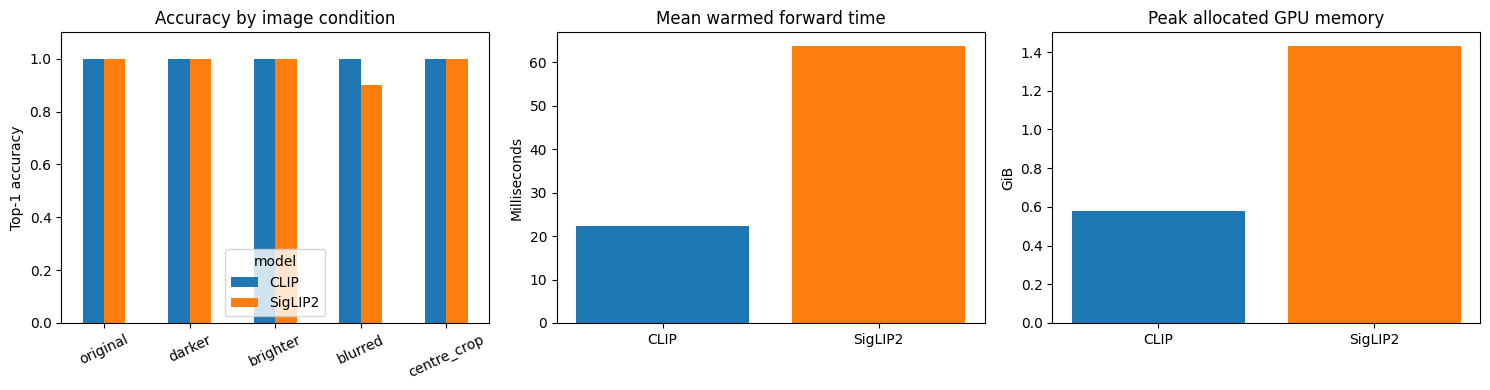

In [3]:
model_order = ["CLIP", "SigLIP2"]
colours = ["tab:blue", "tab:orange"]
condition_order = [
    "original", "darker", "brighter", "blurred", "centre_crop"
]

accuracy_table = (
    condition_summary["top1_accuracy"]
    .unstack("model")
    .reindex(condition_order)[model_order]
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

accuracy_table.plot.bar(
    ax=axes[0], color=colours, rot=25
)
axes[0].set_ylim(0, 1.1)
axes[0].set_ylabel("Top-1 accuracy")
axes[0].set_xlabel("")
axes[0].set_title("Accuracy by image condition")

axes[1].bar(
    model_order,
    summary.loc[model_order, "mean_forward_ms"],
    color=colours,
)
axes[1].set_ylabel("Milliseconds")
axes[1].set_title("Mean warmed forward time")

axes[2].bar(
    model_order,
    summary.loc[model_order, "peak_allocated_gpu_gib"],
    color=colours,
)
axes[2].set_ylabel("GiB")
axes[2].set_title("Peak allocated GPU memory")

fig.tight_layout()
fig.savefig(
    evaluation / "model_comparison.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

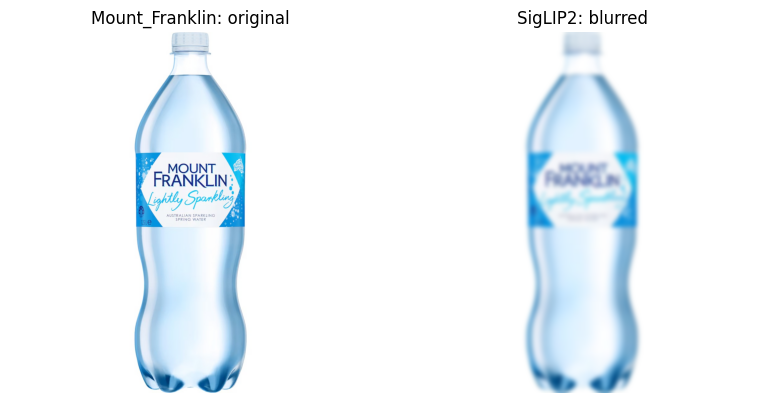

Expected: Mount_Franklin
Predicted: Coca_Cola


,candidate,rank,score
730,Coca_Cola,1,-4.077837
731,Mount_Franklin,2,-4.146868
732,Red_Bull,3,-10.413826


In [4]:
if errors.empty:
    print("No top-1 errors.")
else:
    for row in errors.itertuples(index=False):
        original_row = manifest[
            (manifest["product"] == row.product)
            & (manifest["condition"] == "original")
        ].iloc[0]

        fig, axes = plt.subplots(1, 2, figsize=(8, 4))

        for ax, path, title in [
            (
                axes[0],
                original_row["image_file"],
                f"{row.product}: original",
            ),
            (
                axes[1],
                row.image_file,
                f"{row.model}: {row.condition}",
            ),
        ]:
            with Image.open(project / path) as image:
                ax.imshow(image)
            ax.set_title(title)
            ax.axis("off")

        fig.tight_layout()
        fig.savefig(
            evaluation / f"error_{row.model}_{row.image_id}.png",
            dpi=180,
            bbox_inches="tight",
        )
        plt.show()

        top_candidates = scores[
            (scores["model"] == row.model)
            & (scores["image_id"] == row.image_id)
        ].sort_values("rank").head(3)

        print("Expected:", row.product)
        print("Predicted:", row.predicted_product)
        display(top_candidates[["candidate", "rank", "score"]])

### Conclusion and limitations
CLIP correctly classified all 50 images, whereas SigLIP2 got 49 right.
Both models correctly classified all ten original images and achieved that.
100% top-3 accuracy.

SigLIP2 mistook the blurry Mount Franklin bottle for Coca-Cola.
The right candidate came in second place, with a small difference in their raw score of 0.069.


CLIP used less measured forward time and GPU memory, making it the
preferred candidate for further testing on this small catalogue.
A single recognition mistake does not prove that something is better overall.

The evaluation uses ten clean product photographs and related
transformations. Detailed descriptions and distinct products make
the task relatively easy. Pretraining overlap is unknown.
Shelf scenes, similar product variants and unknown products remain
untested. The classifier always selects a known candidate.



In [5]:
import shutil
from google.colab import files

backup = shutil.make_archive(
    "/content/pair4_evaluated_backup",
    "zip",
    root_dir=str(project),
)

files.download(backup)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>